# 04 · Model 2 — Random Forest

**Idea:** build **many decision trees**, each on a random sample of the rows and features.
The final prediction is the **average of all trees**.

* A single tree is unstable; averaging many trees makes the prediction **stable and accurate**.
* Handles **non-linear** patterns ("flat, then drop") and needs **no scaling**.


> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from utils import load_features, evaluate, plot_validation, plot_test, stage_table, save_results, savefig
from utils import COLORS, MODELS, RUL_CAP, SEED

NAME = "Random Forest"

## 1. Load the features (made in notebook 02)

In [2]:
train, test, FEATURES = load_features()
tr = train[train["split"] == "train"]
val = train[train["split"] == "val"]

X_train, y_train, groups = tr[FEATURES], tr["RUL"], tr["unit"]
X_val, y_val = val[FEATURES], val["RUL"]
print(f"Training engines: {tr['unit'].nunique()} | Validation engines: {val['unit'].nunique()} | Features: {len(FEATURES)}")

Training engines: 80 | Validation engines: 20 | Features: 71


## 2. Train and tune the model
We try a few settings with **GridSearchCV** and keep the best one.

* **3-fold `GroupKFold`** on the 80 training engines → one engine is never in two folds (no leakage).
* Score = **RMSE** (lower is better).
* The 20 validation engines are **not** used here — only afterwards, to compare models fairly.

In [3]:
base_model = RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1)   # 150 trees
param_grid = {"max_depth": [10, 20],            # how deep each tree can grow
              "min_samples_leaf": [5, 20]}      # minimum rows in a leaf (bigger = smoother)

search = GridSearchCV(base_model, param_grid, cv=GroupKFold(n_splits=3),
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train, groups=groups)
model = search.best_estimator_
print("Best settings:", search.best_params_)

Best settings: {'max_depth': 20, 'min_samples_leaf': 5}


## 3. Results on the validation engines
* **RMSE** — typical error in cycles (big mistakes count more)
* **MAE** — average error in cycles
* **R²** — how much of the variation is explained (1 = perfect)

In [4]:
val_pred = np.clip(model.predict(X_val), 0, RUL_CAP)     # RUL can't be below 0 or above the cap
pd.DataFrame([evaluate(y_val, val_pred)], index=[NAME + " (validation)"])

,RMSE,MAE,R2
Random Forest (validation),10.34,6.77,0.939


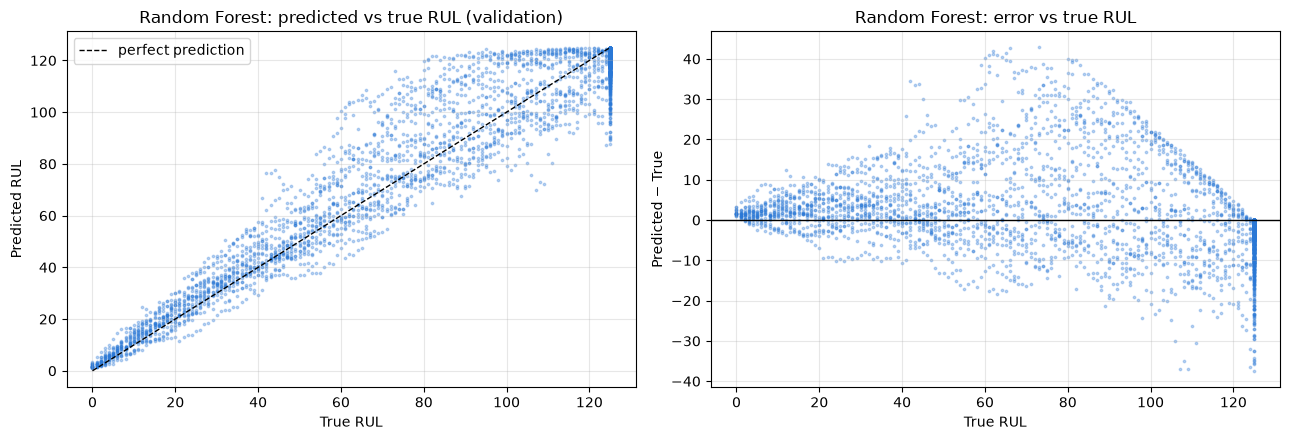

In [5]:
plot_validation(NAME, y_val, val_pred, "04_validation")

**How to read:** left — points on the dashed line are perfect predictions. Right — points above 0 mean the model
predicted **too much** life left (dangerous), below 0 means **too little** (safe but wasteful).

## 4. Which features matter?
Feature importance = how much each feature reduced the error inside the trees.

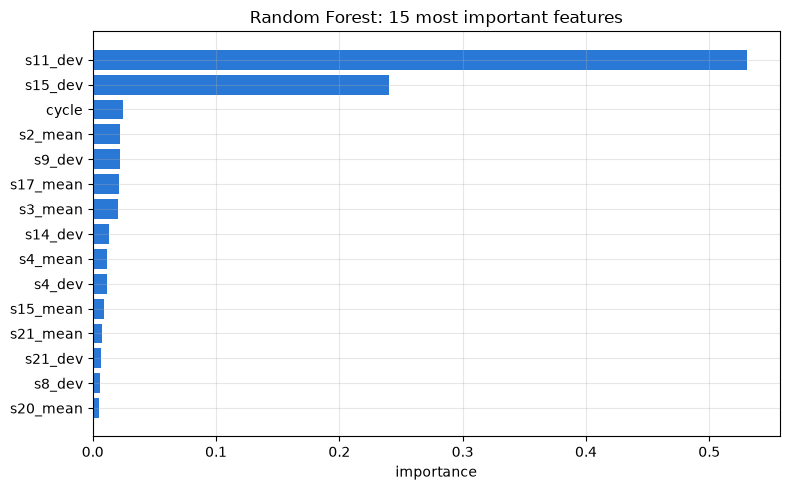

,importance %
dev,85.5
mean,11.0
cycle,2.4
std,0.8
slope,0.2
raw sensor,0.1


In [6]:
imp = pd.Series(model.feature_importances_, index=FEATURES, dtype=float)
top = imp.nlargest(15)
plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top.values[::-1], color=COLORS[NAME])
plt.title(f"{NAME}: 15 most important features"); plt.xlabel("importance")
savefig("04_feature_importance")

# Which TYPE of feature matters most? (sum of importances per type)
ftype = lambda f: f.split("_")[1] if "_" in f else ("cycle" if f == "cycle" else "raw sensor")
(imp.groupby(ftype).sum().sort_values(ascending=False) * 100).round(1).to_frame("importance %")

## 5. Do the engineered features help?
Same model, same settings, but trained with **only the raw sensors + cycle** (15 features instead of 71).

In [7]:
RAW = [f for f in FEATURES if "_" not in f]   # cycle + 14 raw sensors
raw_model = clone(model).fit(X_train[RAW], y_train)
raw_rmse = evaluate(y_val, np.clip(raw_model.predict(val[RAW]), 0, RUL_CAP))["RMSE"]
eng_rmse = evaluate(y_val, val_pred)["RMSE"]

pd.DataFrame({"Validation RMSE": [raw_rmse, eng_rmse]},
             index=["Raw sensors only (15 features)", "With engineered features (71)"])

,Validation RMSE
Raw sensors only (15 features),15.98
With engineered features (71),10.34


## 6. Early vs late life
* **Early:** true RUL > 100 (engine still healthy)
* **Late:** true RUL ≤ 100 (engine is wearing out — the important part for maintenance)

In [8]:
stage_table(val["RUL_raw"], y_val, val_pred)

,Rows,RMSE,MAE
Stage,,,
early (RUL > 100),2050,8.01,4.97
late (RUL ≤ 100),2020,12.26,8.59


## 7. Official NASA test set (100 engines)
* Re-train the model with the same settings on **all 100 training engines**.
* Predict each test engine **once, at its last recorded cycle**, and compare with the true RUL from `RUL_FD001.txt`.
* Nothing is tuned on the test set.

In [9]:
final_model = clone(model).fit(train[FEATURES], train["RUL"])
test_pred = np.clip(final_model.predict(test[FEATURES]), 0, RUL_CAP)
pd.DataFrame([evaluate(test["RUL"], test_pred)], index=[NAME + " (test)"])

,RMSE,MAE,R2
Random Forest (test),11.44,8.27,0.918


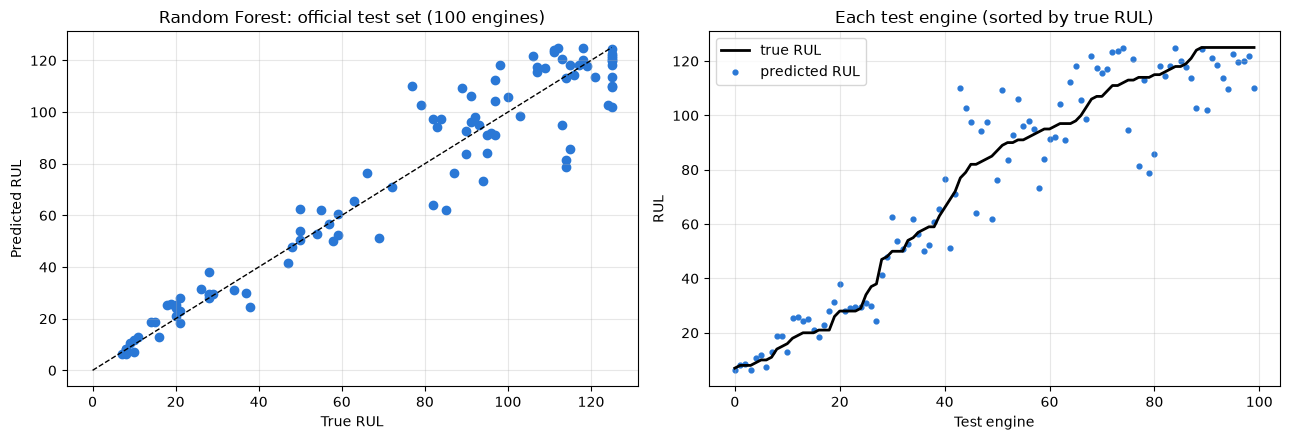

In [10]:
plot_test(NAME, test["RUL"], test_pred, "04_test")

## 8. Save the model and predictions (used by notebook 06 and the web app)

In [11]:
joblib.dump(final_model, MODELS / "random_forest.joblib")
save_results(NAME, val, val_pred, test, test_pred, raw_rmse)

Saved predictions for Random Forest in outputs/results/


## ✅ Summary — Random Forest
* Much better than Elastic Net, because trees can learn the **non-linear** degradation pattern.
* The **`_dev` features** (drift from the engine's own healthy start) dominate the importance.

**Viva quick answers**
* *Why no scaling?* Trees only compare a feature with a threshold, so the units do not matter.
* *What is "bagging"?* Each tree is trained on a random sample (bootstrap) of rows; averaging them reduces variance.